In [3]:
print("Which financial indicator — credit, money supply, bank branches, ATMs, or FDI — correlates most strongly with GDP growth in normal times, and does the ranking shift between income groups?")

Which financial indicator — credit, money supply, bank branches, ATMs, or FDI — correlates most strongly with GDP growth in normal times, and does the ranking shift between income groups?


In [ ]:
#looking up all variables currently stored in the notebooks memory

%whos

Variable                  Type           Data/Info
--------------------------------------------------
DATA_DIR                  WindowsPath    ..\..\data
PAN_DIR                   WindowsPath    ..\..\data\processed
Path                      type           <class 'pathlib.Path'>
country_meta              DataFrame      Shape: (265, 5)
country_meta_gdp          DataFrame      Shape: (265, 5)
country_meta_gdp_path     WindowsPath    ..\..\data\Metadata_Country_GDP.csv
country_meta_path         WindowsPath    ..\..\data\Metadata_Country.csv
df                        DataFrame      Shape: (20216, 68)
df_gdp                    DataFrame      Shape: (266, 68)
df_panel                  DataFrame      Shape: (3831, 12)
gdp_path                  WindowsPath    ..\..\data\DataSheet_GDP.csv
indicator_meta            DataFrame      Shape: (76, 4)
indicator_meta_gdp        DataFrame      Shape: (1, 4)
indicator_meta_gdp_path   WindowsPath    ..\..\data\Metadata_Indicator_GDP.csv
indicator_meta_path

In [ ]:
#Import libraries needed for SQ2.
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

#Define folders.
DATA_DIR = Path("../../data")
PAN_DIR = DATA_DIR / "processed"

#Load the prepared country-year panel.
df_panel = pd.read_csv(PAN_DIR / "financial_panel_2004_2021.csv")

#Load metadata because SQ2 compares results by income group.
country_meta = pd.read_csv(DATA_DIR / "Metadata_Country.csv")

display(df_panel.head())
print(df_panel.shape)
display(country_meta.head())

,Country Name,Year,atms,nonperforming_loans,broad_money,bank_branches,domestic_credit,fdi_inflows,gdp_growth,inflation,interest_spread,market_cap
0,Afghanistan,2004,0.02,NaN,NaN,0.37,NaN,3.577104,1.414118,11.271432,NaN,NaN
1,Afghanistan,2005,0.06,NaN,NaN,0.58,NaN,4.368673,11.229715,10.912774,NaN,NaN
2,Afghanistan,2006,0.12,NaN,23.343865,0.92,4.842857,3.413773,5.357403,7.199751,NaN,NaN
3,Afghanistan,2007,0.21,NaN,23.833664,1.24,6.839982,1.935702,13.826320,22.527756,NaN,NaN
4,Afghanistan,2008,0.30,NaN,29.512281,1.48,9.388328,0.455360,3.924984,2.096289,NaN,NaN


(3831, 12)


,Country Code,Region,IncomeGroup,SpecialNotes,TableName,Unnamed: 5
0,ABW,Latin America & Caribbean,High income,NaN,Aruba,NaN
1,AFE,NaN,NaN,"26 countries, stretching from the Red Sea in t...",Africa Eastern and Southern,NaN
2,AFG,South Asia,Low income,The reporting period for national accounts dat...,Afghanistan,NaN
3,AFW,NaN,NaN,"22 countries, stretching from the westernmost ...",Africa Western and Central,NaN
4,AGO,Sub-Saharan Africa,Lower middle income,The World Bank systematically assesses the app...,Angola,NaN


In [6]:
display(df_panel.head())
print(df_panel.shape)
print(df_panel.columns)
#Count missing values in each column.
#This helps us see which variables have enough data for correlation analysis.
print(df_panel.isna().sum())

,Country Name,Year,atms,nonperforming_loans,broad_money,bank_branches,domestic_credit,fdi_inflows,gdp_growth,inflation,interest_spread,market_cap
0,Afghanistan,2004,0.02,NaN,NaN,0.37,NaN,3.577104,1.414118,11.271432,NaN,NaN
1,Afghanistan,2005,0.06,NaN,NaN,0.58,NaN,4.368673,11.229715,10.912774,NaN,NaN
2,Afghanistan,2006,0.12,NaN,23.343865,0.92,4.842857,3.413773,5.357403,7.199751,NaN,NaN
3,Afghanistan,2007,0.21,NaN,23.833664,1.24,6.839982,1.935702,13.826320,22.527756,NaN,NaN
4,Afghanistan,2008,0.30,NaN,29.512281,1.48,9.388328,0.455360,3.924984,2.096289,NaN,NaN


(3831, 12)
Index(['Country Name', 'Year', 'atms', 'nonperforming_loans', 'broad_money',
       'bank_branches', 'domestic_credit', 'fdi_inflows', 'gdp_growth',
       'inflation', 'interest_spread', 'market_cap'],
      dtype='str')
Country Name              0
Year                      0
atms                    850
nonperforming_loans    1983
broad_money            1029
bank_branches           689
domestic_credit         841
fdi_inflows             367
gdp_growth               79
inflation               117
interest_spread        1650
market_cap             2502
dtype: int64


In [7]:
#Check which country names from the panel do not match the metadata names.
#This helps us identify countries that need manual name fixes before merging.
missing_country_matches = sorted(
    set(df_panel["Country Name"]) - set(country_meta["TableName"])
)

display(missing_country_matches)

["Cote d'Ivoire",
 'Curacao',
 'Puerto Rico (US)',
 'Sao Tome and Principe',
 'Somalia, Fed. Rep.',
 'Turkiye']

In [8]:
display(country_meta.head())

,Country Code,Region,IncomeGroup,SpecialNotes,TableName,Unnamed: 5
0,ABW,Latin America & Caribbean,High income,NaN,Aruba,NaN
1,AFE,NaN,NaN,"26 countries, stretching from the Red Sea in t...",Africa Eastern and Southern,NaN
2,AFG,South Asia,Low income,The reporting period for national accounts dat...,Afghanistan,NaN
3,AFW,NaN,NaN,"22 countries, stretching from the westernmost ...",Africa Western and Central,NaN
4,AGO,Sub-Saharan Africa,Lower middle income,The World Bank systematically assesses the app...,Angola,NaN


In [9]:
#create a seoarate SQ2 working copy
#this keeps the original panel unchanged

df_sq2_base = df_panel.copy()

#create a helper column for merging with the country metadata

df_sq2_base["country_merge_name"] = df_sq2_base["Country Name"]

#Fix country names that differ between df_panel and country_meta.
#These differences would otherwise lead to missing IncomeGroup values.

name_fixes = {
    "Cote d'Ivoire": "Côte d'Ivoire",
    "Curacao": "Curaçao",
    "Sao Tome and Principe": "São Tomé and Principe",
    "Turkiye": "Türkiye",
    "Puerto Rico (US)": "Puerto Rico",
    "Somalia, Fed. Rep.": "Somalia"
}


#Apply the name corrections before merging.
df_sq2_base["country_merge_name"] = df_sq2_base["country_merge_name"].replace(name_fixes)

display(df_sq2_base)

,Country Name,Year,atms,nonperforming_loans,broad_money,bank_branches,domestic_credit,fdi_inflows,gdp_growth,inflation,interest_spread,market_cap,country_merge_name
0,Afghanistan,2004,0.02,NaN,NaN,0.37,NaN,3.577104,1.414118,11.271432,NaN,NaN,Afghanistan
1,Afghanistan,2005,0.06,NaN,NaN,0.58,NaN,4.368673,11.229715,10.912774,NaN,NaN,Afghanistan
2,Afghanistan,2006,0.12,NaN,23.343865,0.92,4.842857,3.413773,5.357403,7.199751,NaN,NaN,Afghanistan
3,Afghanistan,2007,0.21,NaN,23.833664,1.24,6.839982,1.935702,13.826320,22.527756,NaN,NaN,Afghanistan
4,Afghanistan,2008,0.30,NaN,29.512281,1.48,9.388328,0.455360,3.924984,2.096289,NaN,NaN,Afghanistan
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3826,Zimbabwe,2017,6.89,NaN,35.467144,5.64,16.875108,1.746885,4.734411,3.056905,3.640000,NaN,Zimbabwe
3827,Zimbabwe,2018,6.63,NaN,14.379262,5.48,5.830265,2.101721,5.009922,200.769578,4.599167,NaN,Zimbabwe
3828,Zimbabwe,2019,6.40,NaN,16.504433,3.75,5.237706,1.142806,-6.332450,225.394648,13.206667,NaN,Zimbabwe
3829,Zimbabwe,2020,6.16,NaN,14.871527,4.17,5.415074,0.699034,-7.816951,604.945864,28.490000,NaN,Zimbabwe


In [10]:
#Create a small lookup table with only the columns needed for the merge.
#TableName contains the country name used in the World Bank metadata.
#IncomeGroup tells us whether a country is low, middle, or high income.
income_lookup = country_meta[
    ["TableName", "IncomeGroup"]
].copy()

display(income_lookup.head())

,TableName,IncomeGroup
0,Aruba,High income
1,Africa Eastern and Southern,NaN
2,Afghanistan,Low income
3,Africa Western and Central,NaN
4,Angola,Lower middle income


In [11]:
#Create a small lookup table for the income group information.
#We only keep the columns needed for the merge.
income_lookup = country_meta[
    ["TableName", "IncomeGroup"]
].copy()

#Merge the income group into the SQ2 dataset.
#country_merge_name is the corrected country name from df_sq2_base.
#TableName is the country name used in the metadata.
#how="left" keeps all rows from df_sq2_base, even if no match is found.
df_sq2 = df_sq2_base.merge(
    income_lookup,
    left_on="country_merge_name",
    right_on="TableName",
    how="left"
)

display(df_sq2)

,Country Name,Year,atms,nonperforming_loans,broad_money,bank_branches,domestic_credit,fdi_inflows,gdp_growth,inflation,interest_spread,market_cap,country_merge_name,TableName,IncomeGroup
0,Afghanistan,2004,0.02,NaN,NaN,0.37,NaN,3.577104,1.414118,11.271432,NaN,NaN,Afghanistan,Afghanistan,Low income
1,Afghanistan,2005,0.06,NaN,NaN,0.58,NaN,4.368673,11.229715,10.912774,NaN,NaN,Afghanistan,Afghanistan,Low income
2,Afghanistan,2006,0.12,NaN,23.343865,0.92,4.842857,3.413773,5.357403,7.199751,NaN,NaN,Afghanistan,Afghanistan,Low income
3,Afghanistan,2007,0.21,NaN,23.833664,1.24,6.839982,1.935702,13.826320,22.527756,NaN,NaN,Afghanistan,Afghanistan,Low income
4,Afghanistan,2008,0.30,NaN,29.512281,1.48,9.388328,0.455360,3.924984,2.096289,NaN,NaN,Afghanistan,Afghanistan,Low income
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3826,Zimbabwe,2017,6.89,NaN,35.467144,5.64,16.875108,1.746885,4.734411,3.056905,3.640000,NaN,Zimbabwe,Zimbabwe,Lower middle income
3827,Zimbabwe,2018,6.63,NaN,14.379262,5.48,5.830265,2.101721,5.009922,200.769578,4.599167,NaN,Zimbabwe,Zimbabwe,Lower middle income
3828,Zimbabwe,2019,6.40,NaN,16.504433,3.75,5.237706,1.142806,-6.332450,225.394648,13.206667,NaN,Zimbabwe,Zimbabwe,Lower middle income
3829,Zimbabwe,2020,6.16,NaN,14.871527,4.17,5.415074,0.699034,-7.816951,604.945864,28.490000,NaN,Zimbabwe,Zimbabwe,Lower middle income


In [12]:
#Check whether there are still countries without an IncomeGroup after the name fixes.
#These rows did not successfully match with the metadata.

missing_after_fix = (
    df_sq2[df_sq2["IncomeGroup"].isna()]
    [["Country Name", "country_merge_name", "TableName"]]
    .drop_duplicates()
    .sort_values("Country Name")
)

display(missing_after_fix)
print(missing_after_fix.shape)

,Country Name,country_merge_name,TableName
3707,"Venezuela, RB","Venezuela, RB","Venezuela, RB"


(1, 3)


In [13]:
#Remove rows where no IncomeGroup was found.
#These countries cannot be used for the income-group comparison in SQ2.
df_sq2 = df_sq2.dropna(subset=["IncomeGroup"]).copy()
#Remove helper columns that were only needed for the merge.
df_sq2 = df_sq2.drop(columns=["country_merge_name", "TableName"])

In [14]:
display(df_sq2)
print(df_sq2.shape)
print(df_sq2.columns)

,Country Name,Year,atms,nonperforming_loans,broad_money,bank_branches,domestic_credit,fdi_inflows,gdp_growth,inflation,interest_spread,market_cap,IncomeGroup
0,Afghanistan,2004,0.02,NaN,NaN,0.37,NaN,3.577104,1.414118,11.271432,NaN,NaN,Low income
1,Afghanistan,2005,0.06,NaN,NaN,0.58,NaN,4.368673,11.229715,10.912774,NaN,NaN,Low income
2,Afghanistan,2006,0.12,NaN,23.343865,0.92,4.842857,3.413773,5.357403,7.199751,NaN,NaN,Low income
3,Afghanistan,2007,0.21,NaN,23.833664,1.24,6.839982,1.935702,13.826320,22.527756,NaN,NaN,Low income
4,Afghanistan,2008,0.30,NaN,29.512281,1.48,9.388328,0.455360,3.924984,2.096289,NaN,NaN,Low income
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3826,Zimbabwe,2017,6.89,NaN,35.467144,5.64,16.875108,1.746885,4.734411,3.056905,3.640000,NaN,Lower middle income
3827,Zimbabwe,2018,6.63,NaN,14.379262,5.48,5.830265,2.101721,5.009922,200.769578,4.599167,NaN,Lower middle income
3828,Zimbabwe,2019,6.40,NaN,16.504433,3.75,5.237706,1.142806,-6.332450,225.394648,13.206667,NaN,Lower middle income
3829,Zimbabwe,2020,6.16,NaN,14.871527,4.17,5.415074,0.699034,-7.816951,604.945864,28.490000,NaN,Lower middle income


(3813, 13)
Index(['Country Name', 'Year', 'atms', 'nonperforming_loans', 'broad_money',
       'bank_branches', 'domestic_credit', 'fdi_inflows', 'gdp_growth',
       'inflation', 'interest_spread', 'market_cap', 'IncomeGroup'],
      dtype='str')


In [ ]:
#Define the target variable for SQ2
#We want to explain or compare financial indicators against GDP growth

target = "gdp_growth"

#These are the five channels whose correlation with GDP growth will be ranked.
financial_indicators = [
    "domestic_credit",
    "broad_money",
    "bank_branches",
    "atms",
    "fdi_inflows"
]

In [16]:
#Select only the columns needed for SQ2.
sq2_data = df_sq2[
    ["Country Name", "Year", "IncomeGroup", target] + financial_indicators
].copy()

display(sq2_data.head())
print(sq2_data.shape)

,Country Name,Year,IncomeGroup,gdp_growth,domestic_credit,broad_money,bank_branches,atms,fdi_inflows
0,Afghanistan,2004,Low income,1.414118,NaN,NaN,0.37,0.02,3.577104
1,Afghanistan,2005,Low income,11.229715,NaN,NaN,0.58,0.06,4.368673
2,Afghanistan,2006,Low income,5.357403,4.842857,23.343865,0.92,0.12,3.413773
3,Afghanistan,2007,Low income,13.826320,6.839982,23.833664,1.24,0.21,1.935702
4,Afghanistan,2008,Low income,3.924984,9.388328,29.512281,1.48,0.30,0.455360


(3813, 9)


In [17]:
#Define crisis years that should be excluded from the "normal times" analysis.
#SQ2 focuses on correlations outside major shocks.
crisis_years = [2008, 2009, 2020, 2021]

#The ~ means "not", so we exclude rows where Year is in crisis_years.
sq2_normal = sq2_data[
    ~sq2_data["Year"].isin(crisis_years)
].copy()

print("Years used:")
print(sorted(sq2_normal["Year"].unique()))

print("Shape after filtering normal times:")
print(sq2_normal.shape)

Years used:
[np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019)]
Shape after filtering normal times:
(2969, 9)


In [18]:

#Create a missing-value overview for the SQ2 normal-times dataset.
#This shows both the number and percentage of missing values per column.
missing_overview = pd.DataFrame({
    "missing_values": sq2_normal.isna().sum(),
    "missing_percent": (sq2_normal.isna().mean() * 100).round(2)
})

display(missing_overview)

,missing_values,missing_percent
Country Name,0,0.00
Year,0,0.00
IncomeGroup,0,0.00
gdp_growth,66,2.22
domestic_credit,638,21.49
broad_money,776,26.14
bank_branches,519,17.48
atms,649,21.86
fdi_inflows,283,9.53


In [19]:
#Create an empty list to store one correlation result per income group and indicator
group_correlations = []

#Loop through each income group separately.
for income_group, group_data in sq2_normal.groupby("IncomeGroup"):

    #For each income group, calculate the correlation for each financial indicator.
    for indicator in financial_indicators:
        #Keep only the current financial indicator and GDP growth.
        #dropna() removes rows where either value is missing, because correlation can only be calculated with complete pairs.
        temp = group_data[[indicator, target]].dropna()
        #Calculate the correlation between the financial indicator and GDP growth.
        #Positive values mean that higher indicator values tend to move together with higher GDP growth.
        #Negative values mean that higher indicator values tend to move together with lower GDP growth.
        correlation = temp[indicator].corr(temp[target])

        #Store the result as one row in our output table.
        group_correlations.append({
            "IncomeGroup": income_group,
            "indicator": indicator,
            "correlation_with_gdp_growth": correlation,
            "abs_correlation": abs(correlation),
            "number_of_observations": len(temp)
        })
#Convert the list of results into a DataFrame.
group_corr_df = pd.DataFrame(group_correlations)

display(group_corr_df)

,IncomeGroup,indicator,correlation_with_gdp_growth,abs_correlation,number_of_observations
0,High income,domestic_credit,-0.215377,0.215377,744
1,High income,broad_money,-0.086404,0.086404,497
2,High income,bank_branches,-0.127734,0.127734,780
3,High income,atms,-0.115132,0.115132,778
4,High income,fdi_inflows,0.001292,0.001292,881
5,Low income,domestic_credit,0.044972,0.044972,286
6,Low income,broad_money,-0.061523,0.061523,290
7,Low income,bank_branches,-0.053957,0.053957,282
8,Low income,atms,-0.123871,0.123871,235
9,Low income,fdi_inflows,0.123136,0.123136,309


In [21]:
#Sort the correlation results within each income group.
#The strongest correlations appear first because we sort by abs_correlation descending.
group_ranking = group_corr_df.sort_values(
    ["IncomeGroup", "abs_correlation"],
    ascending=[True, False]
).copy()

display(group_ranking)

,IncomeGroup,indicator,correlation_with_gdp_growth,abs_correlation,number_of_observations
0,High income,domestic_credit,-0.215377,0.215377,744
2,High income,bank_branches,-0.127734,0.127734,780
3,High income,atms,-0.115132,0.115132,778
1,High income,broad_money,-0.086404,0.086404,497
4,High income,fdi_inflows,0.001292,0.001292,881
8,Low income,atms,-0.123871,0.123871,235
9,Low income,fdi_inflows,0.123136,0.123136,309
6,Low income,broad_money,-0.061523,0.061523,290
7,Low income,bank_branches,-0.053957,0.053957,282
5,Low income,domestic_credit,0.044972,0.044972,286


In [25]:
# Create a clean display table for the SQ2 ranking.
group_ranking_display = group_ranking[
    [
        "IncomeGroup",
        "indicator",
        "correlation_with_gdp_growth",
        "abs_correlation",
        "number_of_observations"
    ]
].copy()

#Round the correlation values to make the table easier to read.
group_ranking_display["correlation_with_gdp_growth"] = (
    group_ranking_display["correlation_with_gdp_growth"].round(3)
)

group_ranking_display["abs_correlation"] = (
    group_ranking_display["abs_correlation"].round(3)
)

display(group_ranking_display)

,IncomeGroup,indicator,correlation_with_gdp_growth,abs_correlation,number_of_observations
0,High income,domestic_credit,-0.215,0.215,744
2,High income,bank_branches,-0.128,0.128,780
3,High income,atms,-0.115,0.115,778
1,High income,broad_money,-0.086,0.086,497
4,High income,fdi_inflows,0.001,0.001,881
8,Low income,atms,-0.124,0.124,235
9,Low income,fdi_inflows,0.123,0.123,309
6,Low income,broad_money,-0.062,0.062,290
7,Low income,bank_branches,-0.054,0.054,282
5,Low income,domestic_credit,0.045,0.045,286


In [26]:
#Keep only the strongest financial indicator per income group.
#This works because group_ranking_display is already sorted by IncomeGroup and abs_correlation from strongest to weakest.
top_indicators = group_ranking_display.groupby("IncomeGroup").head(1)

display(top_indicators)

,IncomeGroup,indicator,correlation_with_gdp_growth,abs_correlation,number_of_observations
0,High income,domestic_credit,-0.215,0.215,744
8,Low income,atms,-0.124,0.124,235
13,Lower middle income,atms,-0.229,0.229,629
18,Upper middle income,atms,-0.131,0.131,663


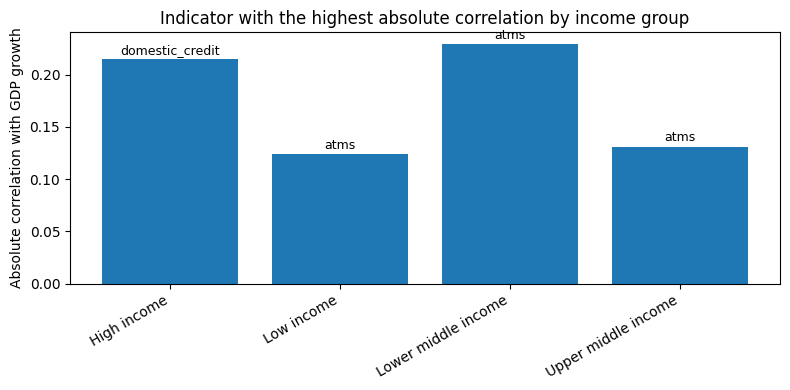

In [66]:
#Create a bar chart showing the strongest correlation per income group.
plt.figure(figsize=(8, 4))

plt.bar(
    top_indicators["IncomeGroup"],
    top_indicators["abs_correlation"]
)

#Rotate x-axis labels so they are easier to read.
plt.xticks(rotation=30, ha="right")
plt.ylabel("Absolute correlation with GDP growth")
plt.title("Indicator with the highest absolute correlation by income group")

#Add the indicator name above each bar.
for index, row in top_indicators.iterrows():
    plt.text(
        x=list(top_indicators.index).index(index),
        y=row["abs_correlation"] + 0.005,
        s=row["indicator"],   # changed from indicator_label to indicator
        ha="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [37]:
#Reshape the correlation results into a matrix.
#Rows are income groups, columns are financial indicators and the values are the correlations with GDP growth.
corr_matrix = group_corr_df.pivot(
    index="IncomeGroup",
    columns="indicator",
    values="correlation_with_gdp_growth"
)

display(corr_matrix.round(3))

indicator,atms,bank_branches,broad_money,domestic_credit,fdi_inflows
IncomeGroup,,,,,
High income,-0.115,-0.128,-0.086,-0.215,0.001
Low income,-0.124,-0.054,-0.062,0.045,0.123
Lower middle income,-0.229,0.034,-0.061,-0.041,0.141
Upper middle income,-0.131,-0.071,-0.069,-0.033,0.081


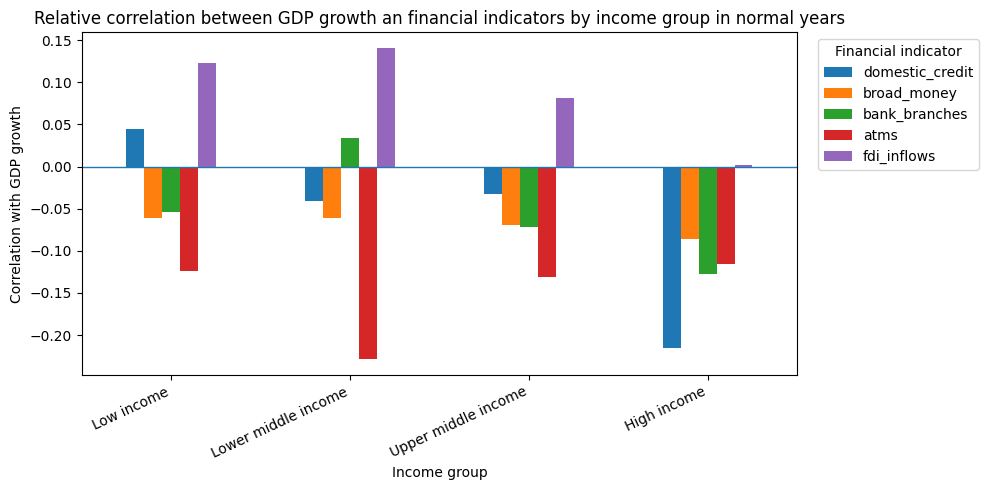

In [ ]:
#Prepare the matrix for the plot.
# Rows are income groups, columns are financial indicators, and values are signed correlations with GDP growth.
plot_data_signed = group_corr_df.pivot(
    index="IncomeGroup",
    columns="indicator",
    values="correlation_with_gdp_growth"
)

#Set the order of income groups in the chart.
income_order = [
    "Low income",
    "Lower middle income",
    "Upper middle income",
    "High income"
]

#Set the order of indicators using the original column names.
indicator_order = [
    "domestic_credit",
    "broad_money",
    "bank_branches",
    "atms",
    "fdi_inflows"
]

#Apply the selected row and column order.
plot_data_signed = plot_data_signed.loc[income_order, indicator_order]

#Create a grouped bar chart with signed correlations.
ax = plot_data_signed.plot(
    kind="bar",
    figsize=(10, 5)
)

#Add a zero line so positive and negative correlations are easy to compare.
plt.axhline(0, linewidth=1)

plt.ylabel("Correlation with GDP growth")
plt.xlabel("Income group")
plt.title("Relative correlation between GDP growth an financial indicators by income group in normal years")
plt.xticks(rotation=25, ha="right")
plt.legend(title="Financial indicator", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [49]:
#Calculate median values of the financial indicators by year and income group.
#The median is used because it is less affected by extreme outliers than the mean.
indicator_trends = (
    df_sq2
    .dropna(subset=["Year", "IncomeGroup"])
    .groupby(["Year", "IncomeGroup"])[financial_indicators]
    .median()
    .reset_index()
)

#Keep only the project period from 2004 to 2021.
indicator_trends = indicator_trends[
    (indicator_trends["Year"] >= 2004) & 
    (indicator_trends["Year"] <= 2021)
].copy()

#Make sure Year is stored as an integer.
#This helps with sorting and plotting time trends.
indicator_trends["Year"] = indicator_trends["Year"].astype(int)


display(indicator_trends.head())

,Year,IncomeGroup,domestic_credit,broad_money,bank_branches,atms,fdi_inflows
0,2004,High income,67.268326,71.825797,27.825,59.040,3.793092
1,2004,Low income,7.160592,18.233091,1.120,0.040,2.173354
2,2004,Lower middle income,17.047785,32.915034,4.730,2.125,1.594525
3,2004,Upper middle income,23.379183,40.454432,10.750,17.535,3.495757
4,2005,High income,72.384880,69.573753,26.590,60.505,4.951054


In [51]:
#Create a copy of the trend dataset.
percent_change_trends = indicator_trends.copy()

#Calculate the percentage change since 2004 for each financial indicator.
#This is necessary because of different units between indicators.
for indicator in financial_indicators:
    
    #Get the 2004 baseline value for each income group.
    #This is the starting point for the percentage change calculation.
    base_2004 = (
        percent_change_trends[percent_change_trends["Year"] == 2004]
        [["IncomeGroup", indicator]]
        .rename(columns={indicator: f"{indicator}_base_2004"})
    )
    
    #Add the 2004 baseline value back to every year of the same income group.
    percent_change_trends = percent_change_trends.merge(
        base_2004,
        on="IncomeGroup",
        how="left"
    )
    
    #Calculate how much the indicator changed compared to 2004.
    #Example: 50 means the value is 50% higher than in 2004.
    percent_change_trends[f"{indicator}_pct_change"] = (
        (percent_change_trends[indicator] - percent_change_trends[f"{indicator}_base_2004"])
        / percent_change_trends[f"{indicator}_base_2004"] * 100
    )

display(percent_change_trends.head())

,Year,IncomeGroup,domestic_credit,broad_money,bank_branches,atms,fdi_inflows,domestic_credit_base_2004,domestic_credit_pct_change,broad_money_base_2004,broad_money_pct_change,bank_branches_base_2004,bank_branches_pct_change,atms_base_2004,atms_pct_change,fdi_inflows_base_2004,fdi_inflows_pct_change
0,2004,High income,67.268326,71.825797,27.825,59.040,3.793092,67.268326,0.000000,71.825797,0.000000,27.825,0.000000,59.040,0.000000,3.793092,0.000000
1,2004,Low income,7.160592,18.233091,1.120,0.040,2.173354,7.160592,0.000000,18.233091,0.000000,1.120,0.000000,0.040,0.000000,2.173354,0.000000
2,2004,Lower middle income,17.047785,32.915034,4.730,2.125,1.594525,17.047785,0.000000,32.915034,0.000000,4.730,0.000000,2.125,0.000000,1.594525,0.000000
3,2004,Upper middle income,23.379183,40.454432,10.750,17.535,3.495757,23.379183,0.000000,40.454432,0.000000,10.750,0.000000,17.535,0.000000,3.495757,0.000000
4,2005,High income,72.384880,69.573753,26.590,60.505,4.951054,67.268326,7.606185,71.825797,-3.135424,27.825,-4.438455,59.040,2.481369,3.793092,30.528202


In [ ]:
#Import plotting tools.
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

#Define the financial indicators used for the trend plots.
financial_indicators = [
    "domestic_credit",
    "broad_money",
    "bank_branches",
    "atms",
    "fdi_inflows"
]

#Add GDP growth to the list of variables we want to plot over time.
all_trend_variables = financial_indicators + ["gdp_growth"]

#Define a fixed order for income groups.
#This keeps plots consistent and easier to compare.
income_order = [
    "Low income",
    "Lower middle income",
    "Upper middle income",
    "High income"
]

#Define one color per income group.
#This keeps the same group visually consistent across all plots.
income_colors = {
    "Low income": "tab:blue",
    "Lower middle income": "tab:orange",
    "Upper middle income": "tab:green",
    "High income": "tab:red"
}

In [ ]:
#Calculate median values by year and income group.
#This prepares trend data for all financial indicators and GDP growth.
trend_data = (
    df_sq2
    .dropna(subset=["Year", "IncomeGroup"])
    .groupby(["Year", "IncomeGroup"])[all_trend_variables]
    .median()
    .reset_index()
)

#Keep only the project period from 2004 to 2021.
trend_data = trend_data[
    (trend_data["Year"] >= 2004) &
    (trend_data["Year"] <= 2021)
].copy()

#Make sure Year is stored as an integer for plotting.
trend_data["Year"] = trend_data["Year"].astype(int)

display(trend_data.head())

,Year,IncomeGroup,domestic_credit,broad_money,bank_branches,atms,fdi_inflows,gdp_growth
0,2004,High income,67.268326,71.825797,27.825,59.040,3.793092,4.218941
1,2004,Low income,7.160592,18.233091,1.120,0.040,2.173354,5.338751
2,2004,Lower middle income,17.047785,32.915034,4.730,2.125,1.594525,5.239533
3,2004,Upper middle income,23.379183,40.454432,10.750,17.535,3.495757,5.300000
4,2005,High income,72.384880,69.573753,26.590,60.505,4.951054,3.485309


In [55]:
#Create a copy of the yearly median trend data.
#We use this copy for the percentage-change plot.
trend_plot_data = trend_data.copy()

#Calculate percentage change since 2004 for each financial indicator.
for indicator in financial_indicators:
    
    #Get the 2004 value for each income group.
    #This becomes the baseline for the percentage change.
    base_2004 = (
        trend_plot_data[trend_plot_data["Year"] == 2004]
        [["IncomeGroup", indicator]]
        .rename(columns={indicator: f"{indicator}_base_2004"})
    )
    
    #Add the 2004 baseline value to all years of the same income group.
    trend_plot_data = trend_plot_data.merge(
        base_2004,
        on="IncomeGroup",
        how="left"
    )
    
    #Calculate the percentage change compared to 2004.
    trend_plot_data[f"{indicator}_pct_change"] = (
        (trend_plot_data[indicator] - trend_plot_data[f"{indicator}_base_2004"])
        / trend_plot_data[f"{indicator}_base_2004"] * 100
    )

In [59]:
#Define crisis years that should be excluded from the normal-years trend analysis.
#This keeps the trend plot consistent with the SQ2 correlation analysis.
crisis_years = [2008, 2009, 2020, 2021]

#Calculate median values by year and income group.
#We use the median to reduce the influence of extreme country values.
trend_data = (
    df_sq2
    .dropna(subset=["Year", "IncomeGroup"])
    .groupby(["Year", "IncomeGroup"])[all_trend_variables]
    .median()
    .reset_index()
)

#Keep only the project period and remove crisis years.
trend_data = trend_data[
    (trend_data["Year"] >= 2004) &
    (trend_data["Year"] <= 2021) &
    (~trend_data["Year"].isin(crisis_years))
].copy()

#Make sure Year is stored as an integer for sorting and plotting.
trend_data["Year"] = trend_data["Year"].astype(int)

#Create a copy for the plot data.
#This copy will include percentage-change columns.
trend_plot_data = trend_data.copy()

#Calculate percentage change since 2004 for each financial indicator.
for indicator in financial_indicators:
    
    #Get the 2004 baseline value for each income group.
    base_2004 = (
        trend_plot_data[trend_plot_data["Year"] == 2004]
        [["IncomeGroup", indicator]]
        .rename(columns={indicator: f"{indicator}_base_2004"})
    )
    
    #Add the 2004 baseline value to all years of the same income group.
    trend_plot_data = trend_plot_data.merge(
        base_2004,
        on="IncomeGroup",
        how="left"
    )
    
    #Calculate the percentage change compared to 2004.
    trend_plot_data[f"{indicator}_pct_change"] = (
        (trend_plot_data[indicator] - trend_plot_data[f"{indicator}_base_2004"])
        / trend_plot_data[f"{indicator}_base_2004"] * 100
    )

#Get the 2004 GDP growth value for each income group.
#GDP growth is already a percentage rate, so we calculate percentage-point change, not percent change.
base_gdp_2004 = (
    trend_plot_data[trend_plot_data["Year"] == 2004]
    [["IncomeGroup", "gdp_growth"]]
    .rename(columns={"gdp_growth": "gdp_growth_base_2004"})
)

#Add the 2004 GDP growth baseline to all years of the same income group.
trend_plot_data = trend_plot_data.merge(
    base_gdp_2004,
    on="IncomeGroup",
    how="left"
)

#Calculate change in GDP growth compared to 2004.
#Example: +2 means GDP growth is 2 percentage points higher than in 2004.
trend_plot_data["gdp_growth_change_since_2004"] = (
    trend_plot_data["gdp_growth"] - trend_plot_data["gdp_growth_base_2004"]
)

#Check the prepared plot data and confirm which years are used.
display(trend_plot_data.head())
print("Years used:", sorted(trend_plot_data["Year"].unique()))

,Year,IncomeGroup,domestic_credit,broad_money,bank_branches,atms,fdi_inflows,gdp_growth,domestic_credit_base_2004,domestic_credit_pct_change,broad_money_base_2004,broad_money_pct_change,bank_branches_base_2004,bank_branches_pct_change,atms_base_2004,atms_pct_change,fdi_inflows_base_2004,fdi_inflows_pct_change,gdp_growth_base_2004,gdp_growth_change_since_2004
0,2004,High income,67.268326,71.825797,27.825,59.040,3.793092,4.218941,67.268326,0.000000,71.825797,0.000000,27.825,0.000000,59.040,0.000000,3.793092,0.000000,4.218941,0.000000
1,2004,Low income,7.160592,18.233091,1.120,0.040,2.173354,5.338751,7.160592,0.000000,18.233091,0.000000,1.120,0.000000,0.040,0.000000,2.173354,0.000000,5.338751,0.000000
2,2004,Lower middle income,17.047785,32.915034,4.730,2.125,1.594525,5.239533,17.047785,0.000000,32.915034,0.000000,4.730,0.000000,2.125,0.000000,1.594525,0.000000,5.239533,0.000000
3,2004,Upper middle income,23.379183,40.454432,10.750,17.535,3.495757,5.300000,23.379183,0.000000,40.454432,0.000000,10.750,0.000000,17.535,0.000000,3.495757,0.000000,5.300000,0.000000
4,2005,High income,72.384880,69.573753,26.590,60.505,4.951054,3.485309,67.268326,7.606185,71.825797,-3.135424,27.825,-4.438455,59.040,2.481369,3.793092,30.528202,4.218941,-0.733632


Years used: [np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019)]


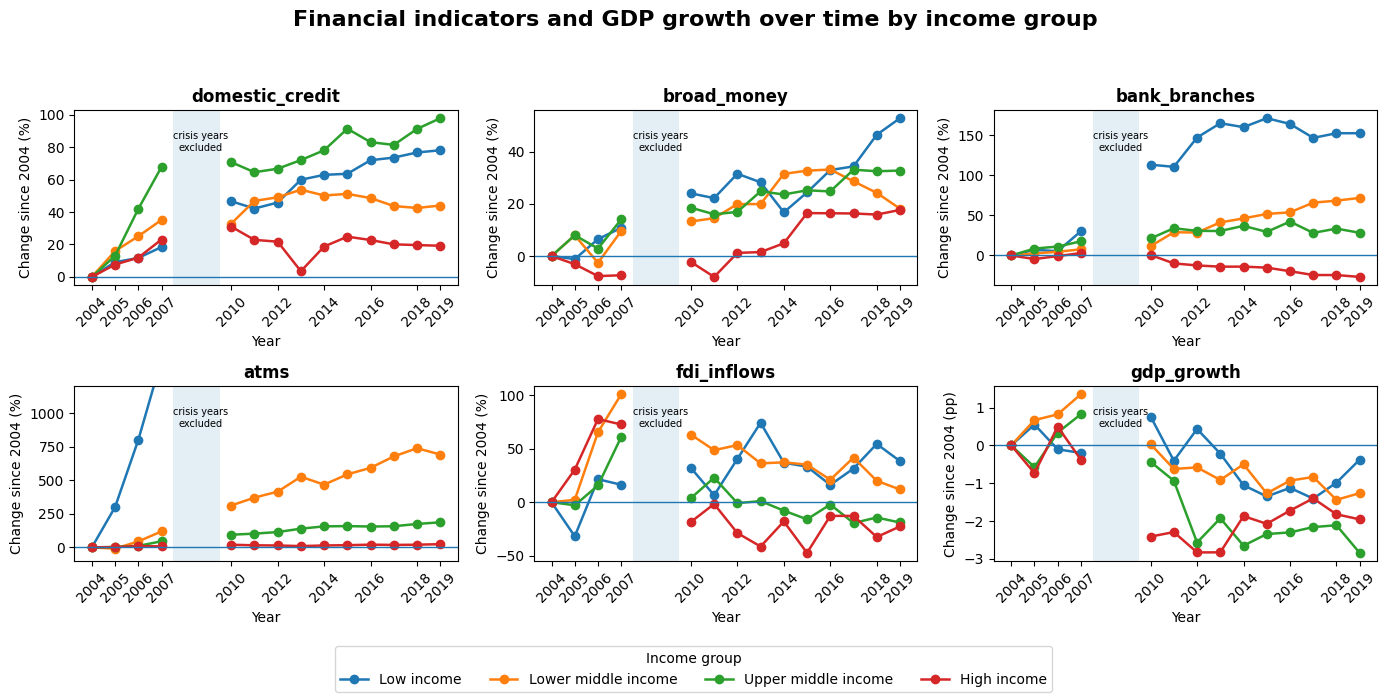

In [60]:
#Create a 2x3 plot layout.
fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(14, 7),
    sharex=False
)

#Flatten the axes so we can loop through them more easily.
axes = axes.flatten()

#Define x-axis ticks for the normal years shown in the plot.
year_ticks = [2004, 2005, 2006, 2007, 2010, 2012, 2014, 2016, 2018, 2019]

#Define normal-year blocks.
#Splitting the years prevents lines from connecting across excluded crisis years.
normal_year_blocks = [
    list(range(2004, 2008)),
    list(range(2010, 2020))
]

#Plot the five financial indicators.
for ax, indicator in zip(axes[:5], financial_indicators):
    
    #Plot one line per income group.
    for income_group in income_order:
        subset_all = trend_plot_data[
            trend_plot_data["IncomeGroup"] == income_group
        ].sort_values("Year")
        
        #Plot each normal-year block separately.
        for block_id, year_block in enumerate(normal_year_blocks):
            subset = subset_all[
                subset_all["Year"].isin(year_block)
            ]
            
            ax.plot(
                subset["Year"],
                subset[f"{indicator}_pct_change"],
                marker="o",
                linewidth=1.8,
                color=income_colors[income_group],
                label=income_group if block_id == 0 else None
            )
    
    #Add baseline and labels.
    ax.axhline(0, linewidth=1)
    ax.set_title(indicator, fontsize=12, fontweight="bold")
    ax.set_ylabel("Change since 2004 (%)")
    ax.set_xlabel("Year")
    ax.set_xticks(year_ticks)
    ax.xaxis.set_major_locator(mticker.FixedLocator(year_ticks))
    ax.xaxis.set_major_formatter(mticker.FormatStrFormatter("%d"))
    ax.tick_params(axis="x", rotation=45)
    
    #Mark the excluded 2008–2009 crisis period.
    ax.axvspan(2007.5, 2009.5, alpha=0.12)
    ax.text(
        0.33, 0.82,
        "crisis years\nexcluded",
        transform=ax.transAxes,
        ha="center",
        va="center",
        fontsize=7
    )
    
    #Limit the ATM panel because low-income ATM growth becomes very large due to a very small 2004 baseline.
    if indicator == "atms":
        ax.set_ylim(-100, 1200)

#Plot GDP growth in the sixth panel.
ax = axes[5]

for income_group in income_order:
    subset_all = trend_plot_data[
        trend_plot_data["IncomeGroup"] == income_group
    ].sort_values("Year")
    
    for block_id, year_block in enumerate(normal_year_blocks):
        subset = subset_all[
            subset_all["Year"].isin(year_block)
        ]
        
        ax.plot(
            subset["Year"],
            subset["gdp_growth_change_since_2004"],
            marker="o",
            linewidth=1.8,
            color=income_colors[income_group],
            label=income_group if block_id == 0 else None
        )

ax.axhline(0, linewidth=1)
ax.set_title("gdp_growth", fontsize=12, fontweight="bold")
ax.set_ylabel("Change since 2004 (pp)")
ax.set_xlabel("Year")
ax.set_xticks(year_ticks)
ax.xaxis.set_major_locator(mticker.FixedLocator(year_ticks))
ax.xaxis.set_major_formatter(mticker.FormatStrFormatter("%d"))
ax.tick_params(axis="x", rotation=45)

# Mark the excluded 2008–2009 crisis period.
ax.axvspan(2007.5, 2009.5, alpha=0.12)
ax.text(
    0.33, 0.82,
    "crisis years\nexcluded",
    transform=ax.transAxes,
    ha="center",
    va="center",
    fontsize=7
)

#Create one shared legend for all panels.
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    title="Income group",
    loc="lower center",
    ncol=4,
    frameon=True
)

fig.suptitle(
    "Financial indicators and GDP growth over time by income group",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0.08, 1, 0.94])
plt.show()